[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wilsonsr/analisis-multivariado-lasalle/blob/main/notebooks/01_fundamentos_y_ACP.ipynb)

# Unidad 1 · Fundamentos del análisis multivariado y Análisis de Componentes Principales

**Análisis Multivariado** · Programa de Ciencia de Datos · Universidad de La Salle
**Unidad 1: Fundamentos y reducción de dimensionalidad en datos multivariados** · Complemento de la *Guía de la Unidad 1*
Autor: Wilson Sandoval Rodríguez (2026)

En este cuaderno vas a:
- Explorar una matriz de datos multivariados: tipos de variables, faltantes y atípicos.
- Calcular el vector de medias y las matrices de covarianzas y correlaciones.
- Decidir entre la matriz de covarianzas y la de correlaciones.
- Aplicar el ACP, elegir el número de componentes e interpretar cargas, contribuciones, cos² y gráficos.
- Hacer un análisis de sensibilidad frente a un valor atípico.

> Los datos son **simulados con fines didácticos**. Las cifras que aparecen en la guía se obtuvieron ejecutando este mismo código con las versiones indicadas en `requirements.txt`. Con otras versiones pueden cambiar el signo de un componente o los últimos decimales.

## 0. Configuración

La primera celda instala las bibliotecas que no vienen en Colab y define desde dónde se leen los datos. Si trabajas en tu computador, clona el repositorio e instala `requirements.txt`.

In [1]:
# Configuración: en Colab instala lo necesario; en local usa los datos del repositorio
import sys, os
EN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

RUTA_LOCAL = os.path.join("..", "data", "datos_guia1_calidad_aire.csv")
RUTA_WEB = "https://raw.githubusercontent.com/wilsonsr/analisis-multivariado-lasalle/main/data/datos_guia1_calidad_aire.csv"
ruta = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else RUTA_WEB

## 1. La matriz de datos

**Caso conductor.** 30 estaciones de monitoreo (filas) con ocho variables cuantitativas: contaminantes (PM2,5, PM10, NO₂, CO, O₃) y meteorología (temperatura, humedad, viento). La zona (industrial, residencial, periurbana) es cualitativa y solo se usará para interpretar.

**Pregunta de análisis:** ¿qué patrones comunes resumen el comportamiento conjunto de contaminantes y meteorología, y cómo se diferencian las estaciones según esos patrones?

In [2]:
datos = pd.read_csv(ruta)
print(datos.shape)              # (n filas, columnas)
datos.head()

(30, 10)


,estacion,zona,PM25,PM10,NO2,CO,O3,Temp,Humedad,Viento
0,E01,Industrial,24.9,47.6,29.7,1.01,29.6,11.9,86,1.7
1,E02,Industrial,24.1,48.2,37.5,1.09,48.0,18.5,66,1.7
2,E03,Industrial,15.6,33.2,28.0,0.87,42.3,17.5,68,2.3
3,E04,Industrial,30.2,61.8,40.7,1.12,41.5,17.1,62,1.2
4,E05,Industrial,29.9,55.5,43.2,1.15,26.7,12.9,75,1.3


In [3]:
print(datos.dtypes)             # tipo de dato de cada columna
X = datos.drop(columns=["estacion", "zona"])   # solo variables cuantitativas
print("Valores faltantes:", int(X.isna().sum().sum()))
X.describe().round(2).T

estacion     object
zona         object
PM25        float64
PM10        float64
NO2         float64
CO          float64
O3          float64
Temp        float64
Humedad       int64
Viento      float64
dtype: object
Valores faltantes: 0


,count,mean,std,min,25%,50%,75%,max
PM25,30.0,18.69,7.12,3.90,15.45,18.50,23.95,30.20
PM10,30.0,35.96,12.89,11.40,29.20,35.20,45.88,61.80
NO2,30.0,28.58,8.41,11.20,22.40,29.20,34.00,43.20
CO,30.0,0.78,0.22,0.36,0.61,0.79,0.98,1.15
O3,30.0,41.96,8.60,26.70,36.00,41.50,47.70,60.10
Temp,30.0,16.10,2.60,11.90,14.22,16.25,18.08,22.40
Humedad,30.0,68.73,7.68,48.00,64.00,68.50,74.50,86.00
Viento,30.0,2.55,0.74,1.20,1.92,2.60,3.20,3.60


**¿Qué observar?** No hay faltantes. Las variables están en escalas muy diferentes: la desviación del PM10 es 12,89 µg/m³ y la del CO 0,22 mg/m³. Esa diferencia será decisiva para el ACP.

## 2. Vector de medias, covarianzas y correlaciones

Primero verifica a mano el ejemplo pequeño de la guía (Tabla 4): cinco estaciones y tres variables.

In [4]:
ejemplo = pd.DataFrame({"PM25": [12, 18, 25, 15, 30],
                        "NO2": [22, 24, 35, 28, 36],
                        "Viento": [3.0, 2.9, 1.8, 2.4, 1.9]}, index=list("ABCDE"))
print("Vector de medias:\n", ejemplo.mean())
print("\nMatriz S (divisor n - 1):\n", ejemplo.cov().round(3))
print("\nMatriz R:\n", ejemplo.corr().round(3))

Vector de medias:
 PM25      20.0
NO2       29.0
Viento     2.4
dtype: float64

Matriz S (divisor n - 1):
          PM25    NO2  Viento
PM25    54.50  42.75  -3.450
NO2     42.75  40.00  -3.450
Viento  -3.45  -3.45   0.305

Matriz R:
          PM25    NO2  Viento
PM25    1.000  0.916  -0.846
NO2     0.916  1.000  -0.988
Viento -0.846 -0.988   1.000


La covarianza entre PM2,5 y NO₂ es 42,75 y su correlación 0,916, como en la guía. Ahora, con el caso completo:

In [5]:
medias = X.mean()                # vector de medias
S = X.cov()                      # matriz de varianzas y covarianzas
R = X.corr()                     # matriz de correlaciones de Pearson
print(medias.round(2))
R.round(2)

PM25       18.69
PM10       35.96
NO2        28.58
CO          0.78
O3         41.96
Temp       16.10
Humedad    68.73
Viento      2.55
dtype: float64


,PM25,PM10,NO2,CO,O3,Temp,Humedad,Viento
PM25,1.00,0.92,0.80,0.92,-0.43,-0.27,0.19,-0.76
PM10,0.92,1.00,0.74,0.86,-0.51,-0.35,0.26,-0.79
NO2,0.80,0.74,1.00,0.78,-0.38,-0.20,0.16,-0.73
CO,0.92,0.86,0.78,1.00,-0.44,-0.25,0.23,-0.79
O3,-0.43,-0.51,-0.38,-0.44,1.00,0.90,-0.83,0.60
Temp,-0.27,-0.35,-0.20,-0.25,0.90,1.00,-0.92,0.45
Humedad,0.19,0.26,0.16,0.23,-0.83,-0.92,1.00,-0.36
Viento,-0.76,-0.79,-0.73,-0.79,0.60,0.45,-0.36,1.00


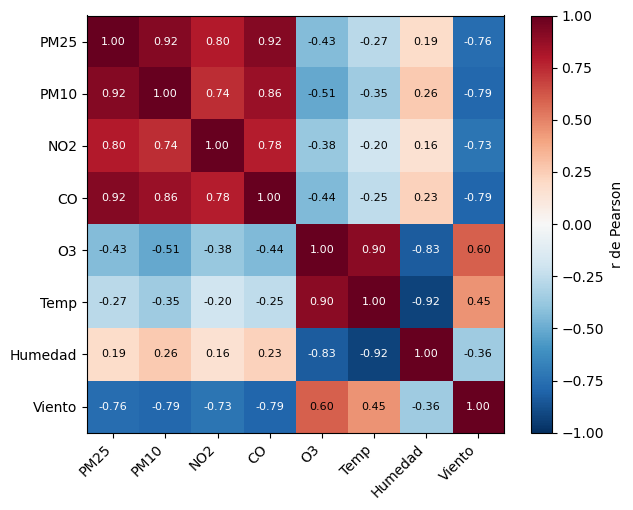

In [6]:
# Mapa de calor de la matriz de correlaciones
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(R)), R.columns, rotation=45, ha="right")
ax.set_yticks(range(len(R)), R.columns)
for i in range(len(R)):
    for j in range(len(R)):
        ax.text(j, i, f"{R.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(R.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="r de Pearson")
plt.tight_layout(); plt.show()

**¿Qué observar?** Dos bloques: PM2,5, PM10, NO₂ y CO (correlaciones de 0,74 a 0,92), opuestos al viento; y O₃–temperatura (0,90), opuestos a la humedad (−0,92). Hay redundancia: el ACP tiene algo que resumir.

## 3. Visualización, faltantes y atípicos

Antes del ACP revisa distribuciones y valores extremos. La regla de 1,5 veces el rango intercuartílico (RIC) señala candidatos a atípicos en cada variable.

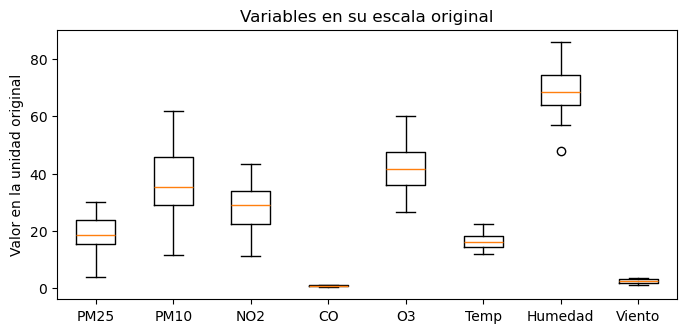

Atípicos por variable:
 PM25       0
PM10       0
NO2        0
CO         0
O3         0
Temp       0
Humedad    1
Viento     0
dtype: int64


,estacion,zona,Humedad
19,E20,Residencial,48


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([X[c] for c in X.columns], tick_labels=X.columns)
ax.set_ylabel("Valor en la unidad original"); ax.set_title("Variables en su escala original")
plt.show()

q1, q3 = X.quantile(0.25), X.quantile(0.75)
ric = q3 - q1
atipicos = (X < q1 - 1.5 * ric) | (X > q3 + 1.5 * ric)
print("Atípicos por variable:\n", atipicos.sum())
datos.loc[atipicos.any(axis=1), ["estacion", "zona", "Humedad"]]

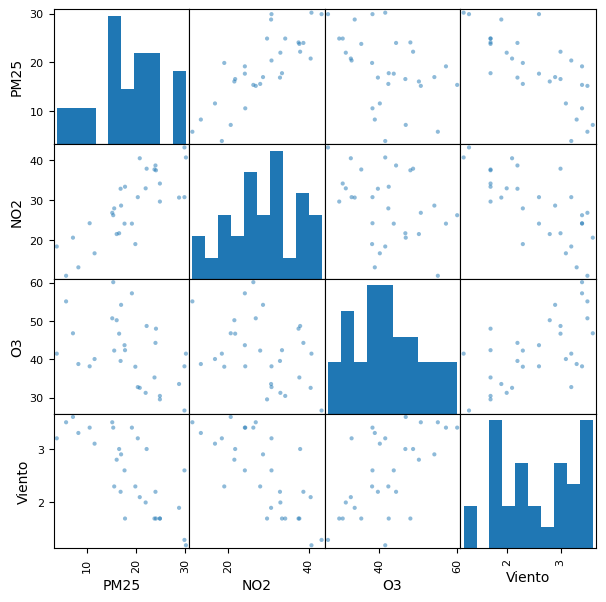

In [8]:
pd.plotting.scatter_matrix(X[["PM25", "NO2", "O3", "Viento"]], figsize=(7, 7), diagonal="hist")
plt.show()

**¿Qué observar?** Solo la humedad de E20 (48 %) aparece como atípica. Es un valor plausible, así que se conserva; en la sección 7 comprobarás si influye en el resultado. Las relaciones por pares son aproximadamente lineales, lo que respalda usar correlaciones de Pearson.

## 4. ¿Covarianzas o correlaciones?

El ACP maximiza varianza. Si las variables están en unidades distintas, la que tenga varianza numéricamente más grande dominará. Compruébalo aplicando el ACP sobre la matriz de covarianzas (datos solo centrados).

In [9]:
print("Varianzas:\n", X.var().round(2))
acp_S = PCA().fit(X - X.mean())
print("\n% de varianza (covarianzas):", (100 * acp_S.explained_variance_ratio_[:3]).round(1))
pd.Series(acp_S.components_[0], index=X.columns).round(2)

Varianzas:
 PM25        50.73
PM10       166.15
NO2         70.72
CO           0.05
O3          73.92
Temp         6.76
Humedad     58.96
Viento       0.54
dtype: float64

% de varianza (covarianzas): [68.1 22.8  5.8]


PM25       0.38
PM10       0.72
NO2        0.40
CO         0.01
O3        -0.34
Temp      -0.08
Humedad    0.20
Viento    -0.04
dtype: float64

**¿Qué observar?** Sobre $\mathbf{S}$, el CP1 explica el 68,1 % y está dominado por el PM10 (peso 0,72); CO, viento y temperatura casi no intervienen. El resultado refleja las unidades, no la estructura. Como las variables están en cinco unidades distintas, el ACP se hará sobre la **matriz de correlaciones** (datos estandarizados).

## 5. ACP sobre datos estandarizados

`StandardScaler` estandariza con divisor $n$; por eso `explained_variance_` de scikit-learn vale $\lambda\cdot n/(n-1)$. Los valores propios de $\mathbf{R}$ se calculan directamente con `eigvalsh`, como en R.

In [10]:
Z = StandardScaler().fit_transform(X)
acp = PCA().fit(Z)
valores_propios = np.linalg.eigvalsh(R)[::-1]
tabla = pd.DataFrame({"valor_propio": valores_propios,
                      "var_%": 100 * acp.explained_variance_ratio_,
                      "acum_%": 100 * np.cumsum(acp.explained_variance_ratio_)},
                     index=[f"CP{k}" for k in range(1, 9)])
print("Suma de valores propios:", valores_propios.sum().round(4))
tabla.round(2)

Suma de valores propios: 8.0


,valor_propio,var_%,acum_%
CP1,5.03,62.88,62.88
CP2,2.07,25.87,88.75
CP3,0.30,3.71,92.46
CP4,0.24,3.02,95.47
CP5,0.15,1.92,97.39
CP6,0.11,1.34,98.73
CP7,0.06,0.79,99.52
CP8,0.04,0.48,100.00


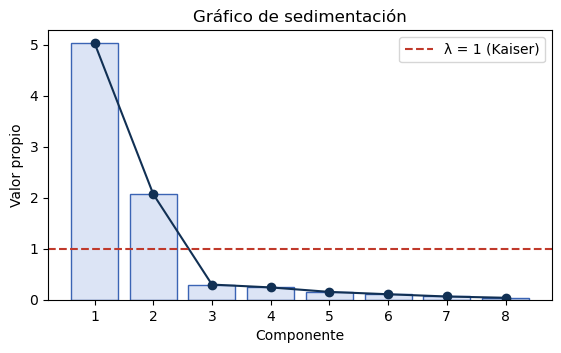

In [11]:
plt.figure(figsize=(6.5, 3.5))
plt.bar(range(1, 9), valores_propios, color="#DCE4F5", edgecolor="#3B64B4")
plt.plot(range(1, 9), valores_propios, marker="o", color="#113054")
plt.axhline(1, ls="--", color="#C0392B", label="λ = 1 (Kaiser)")
plt.xlabel("Componente"); plt.ylabel("Valor propio"); plt.legend(); plt.title("Gráfico de sedimentación")
plt.show()

**¿Qué observar?** λ₁ = 5,03 (62,88 %) y λ₂ = 2,07 (25,87 %): 88,75 % acumulado. λ₃ = 0,30 cae después del codo. Kaiser, varianza acumulada y codo coinciden: **se retienen dos componentes**.

## 6. Cargas, contribuciones y calidad de representación

- **Carga:** $\operatorname{cor}(Z_j, Y_k) = a_{jk}\sqrt{\lambda_k}$.
- **Contribución (%):** $100\,a_{jk}^2$; la referencia es el promedio $100/p = 12{,}5$ %.
- **cos²:** carga al cuadrado; sumado en CP1 y CP2 mide la representación en el plano.

El signo de cada componente es arbitrario. Se orienta con una regla basada en los datos (PM2,5 positivo en CP1 y temperatura positiva en CP2) para que la lectura no dependa de la versión del programa.

In [12]:
lam = valores_propios[:2]
cargas = acp.components_[:2].T * np.sqrt(lam)
puntajes = acp.transform(Z)[:, :2]
for k, var in enumerate(["PM25", "Temp"]):          # orientación de signos
    if cargas[X.columns.get_loc(var), k] < 0:
        cargas[:, k] *= -1
        puntajes[:, k] *= -1

tabla_cargas = pd.DataFrame(cargas, index=X.columns, columns=["CP1", "CP2"])
tabla_cargas["contrib_CP1_%"] = 100 * cargas[:, 0]**2 / lam[0]
tabla_cargas["contrib_CP2_%"] = 100 * cargas[:, 1]**2 / lam[1]
tabla_cargas["cos2_plano"] = cargas[:, 0]**2 + cargas[:, 1]**2
tabla_cargas.round(3)

,CP1,CP2,contrib_CP1_%,contrib_CP2_%,cos2_plano
PM25,0.876,0.393,15.262,7.474,0.922
PM10,0.893,0.288,15.863,3.999,0.881
NO2,0.792,0.392,12.461,7.434,0.781
CO,0.873,0.372,15.159,6.669,0.901
O3,-0.763,0.581,11.574,16.333,0.920
Temp,-0.628,0.755,7.838,27.539,0.964
Humedad,0.559,-0.784,6.204,29.683,0.926
Viento,-0.887,-0.134,15.641,0.869,0.805


**¿Qué observar?**
- **CP1 (62,9 %)**: cargas positivas en PM10, PM2,5, CO, NO₂ y, moderada, en humedad; negativas en viento, O₃ y temperatura. Nombre propuesto: *contaminación primaria frente a ventilación y ozono*.
- **CP2 (25,9 %)**: temperatura y O₃ positivos; humedad negativa. Nombre propuesto: *condiciones térmicas y fotoquímicas*.
- Todas las variables tienen cos² en el plano mayor que 0,78.

## 7. Representaciones gráficas

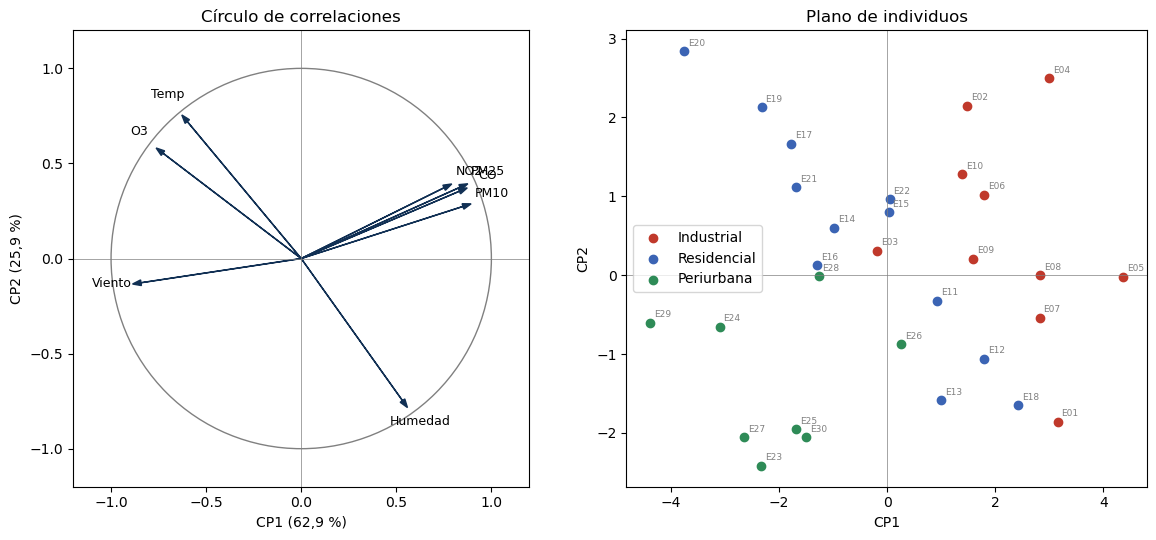

              CP1   CP2
zona                   
Industrial   2.22  0.50
Periurbana  -2.08 -1.33
Residencial -0.47  0.47
    CP1   CP2        zona estacion
4  4.37 -0.02  Industrial      E05
0  3.15 -1.86  Industrial      E01
3  2.99  2.49  Industrial      E04


In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
ax = axs[0]                                           # círculo de correlaciones
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="gray"))
for v, (a, b) in zip(X.columns, cargas):
    ax.arrow(0, 0, a, b, head_width=0.03, length_includes_head=True, color="#113054")
    ax.text(a * 1.12, b * 1.12, v, ha="center", fontsize=9)
ax.axhline(0, lw=0.5, color="gray"); ax.axvline(0, lw=0.5, color="gray")
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
ax.set_xlabel("CP1 (62,9 %)"); ax.set_ylabel("CP2 (25,9 %)"); ax.set_title("Círculo de correlaciones")

ax = axs[1]                                           # plano de individuos por zona
colores = {"Industrial": "#C0392B", "Residencial": "#3B64B4", "Periurbana": "#2E8B57"}
for z, c in colores.items():
    m = (datos["zona"] == z).values
    ax.scatter(puntajes[m, 0], puntajes[m, 1], color=c, label=z)
for i, e in enumerate(datos["estacion"]):
    ax.text(puntajes[i, 0] + 0.07, puntajes[i, 1] + 0.07, e, fontsize=6.5, color="gray")
ax.axhline(0, lw=0.5, color="gray"); ax.axvline(0, lw=0.5, color="gray")
ax.set_xlabel("CP1"); ax.set_ylabel("CP2"); ax.legend(); ax.set_title("Plano de individuos")
plt.tight_layout(); plt.show()

resumen = pd.DataFrame(puntajes, columns=["CP1", "CP2"]).assign(zona=datos["zona"], estacion=datos["estacion"])
print(resumen.groupby("zona")[["CP1", "CP2"]].mean().round(2))
print(resumen.sort_values("CP1", ascending=False).head(3).round(2))

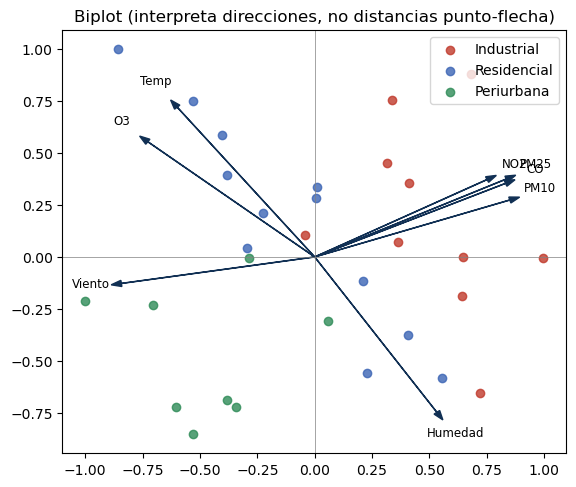

In [14]:
# Biplot: puntajes reescalados al rango [-1, 1] y flechas con las cargas
esc = puntajes / np.abs(puntajes).max(axis=0)
plt.figure(figsize=(6.5, 5.5))
for z, c in colores.items():
    m = (datos["zona"] == z).values
    plt.scatter(esc[m, 0], esc[m, 1], color=c, label=z, alpha=0.8)
for v, (a, b) in zip(X.columns, cargas):
    plt.arrow(0, 0, a, b, head_width=0.03, length_includes_head=True, color="#113054")
    plt.text(a * 1.1, b * 1.1, v, fontsize=8.5, ha="center")
plt.axhline(0, lw=0.5, color="gray"); plt.axvline(0, lw=0.5, color="gray")
plt.legend(); plt.title("Biplot (interpreta direcciones, no distancias punto-flecha)")
plt.show()

**¿Qué observar?** Las estaciones industriales se ubican a la derecha (centro en CP1 = 2,22) y las periurbanas a la izquierda y abajo (CP1 = −2,08; CP2 = −1,33). Las de mayor puntuación en CP1 son E05 (4,37) y E01 (3,15). La zona no participó en el cálculo: su separación en el plano es un resultado.

## 8. Análisis de sensibilidad: ¿influye el atípico de humedad?

In [15]:
sin_E20 = datos[datos["estacion"] != "E20"]
X2 = sin_E20.drop(columns=["estacion", "zona"])
acp2 = PCA().fit(StandardScaler().fit_transform(X2))
print("% de varianza sin E20:", (100 * acp2.explained_variance_ratio_[:2]).round(1),
      "acumulado:", round(100 * acp2.explained_variance_ratio_[:2].sum(), 1))
c2 = acp2.components_[:2].T * np.sqrt(np.linalg.eigvalsh(X2.corr())[::-1][:2])
for k, var in enumerate(["PM25", "Temp"]):
    if c2[X2.columns.get_loc(var), k] < 0:
        c2[:, k] *= -1
pd.DataFrame(c2, index=X2.columns, columns=["CP1", "CP2"]).round(2)

% de varianza sin E20: [61.5 26.8] acumulado: 88.3


,CP1,CP2
PM25,0.90,0.35
PM10,0.88,0.34
NO2,0.82,0.33
CO,0.88,0.35
O3,-0.73,0.61
Temp,-0.58,0.79
Humedad,0.49,-0.82
Viento,-0.88,-0.13


**¿Qué observar?** Sin E20 los dos componentes explican 61,5 % y 26,8 % (88,3 % acumulado) y las cargas conservan su signo y su orden. La interpretación es robusta frente a ese valor.

> **Recuerda:** el ACP describe correlaciones entre variables; no permite afirmar que el viento *cause* menos contaminación.

### ✍️ Tu turno

Repite el ACP usando **solo los cinco contaminantes** (PM25, PM10, NO2, CO, O3). ¿Cuánta varianza explican el primer componente y los dos primeros? ¿Cuántos componentes retendrías y por qué?

*Pista:* reutiliza el código de la sección 5 cambiando la selección de columnas.

<details>
<summary><b>Ver una solución posible</b></summary>

```python
X5 = datos[["PM25", "PM10", "NO2", "CO", "O3"]]
ev5 = np.linalg.eigvalsh(X5.corr())[::-1]
print(ev5.round(2), (100 * ev5 / 5).round(1))
```

Con los cinco contaminantes, los valores propios son 3,79; 0,73; 0,29; 0,13; 0,06. El primer componente explica el 75,8 % y los dos primeros el 90,5 %. Por el criterio de Kaiser (solo el primer valor propio supera 1) y el codo se retendría un solo componente, aunque el segundo (14,6 %) puede revisarse si aporta una interpretación útil. Sin las variables meteorológicas, el ozono queda como la única variable que se opone a los contaminantes primarios.

</details>

---
### Conecta con tu proyecto

Repite este flujo con la base de tu equipo. Guarda el cuaderno con salidas y verifica que se ejecute de principio a fin (*Entorno de ejecución → Reiniciar y ejecutar todo*) antes de entregarlo.

**Siguiente cuaderno:** `02a_correspondencias_simple_y_multiple.ipynb`